# 🔍 EDA: Accident Intelligence Agent
**Dataset**: Accidentalidad vial Madrid 2020  
**Objetivo**: Entender patrones, detectar riesgos y preparar insights para dashboard  
**Autor**: Juan Luis León Rodríguez | **Fecha**: Diciembre 2025  
**Stack**: Python, Pandas, Seaborn, Plotly

In [1]:
# 🔧 AUTO-INSTALACIÓN DE DEPENDENCIAS (solo si faltan)
import sys
import subprocess

def instalar_si_falta(paquete):
    try:
        __import__(paquete)
        print(f"✅ {paquete} ya instalado")
    except ImportError:
        print(f" Instalando {paquete}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", paquete, "-q"])
        print(f"✅ {paquete} instalado")

# Instalar solo lo necesario
paquetes = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'plotly', 'pathlib']
for pkg in paquetes:
    instalar_si_falta(pkg)

print("\n🎉 Todas las dependencias listas. Ejecuta la siguiente celda.")

✅ pandas ya instalado
✅ numpy ya instalado
✅ matplotlib ya instalado
✅ seaborn ya instalado
✅ plotly ya instalado
✅ pathlib ya instalado

🎉 Todas las dependencias listas. Ejecuta la siguiente celda.


In [2]:
# 📦 IMPORTS Y CONFIGURACIÓN INICIAL
# -----------------------------------
# Pandas y NumPy: manipulación de datos
import pandas as pd
import numpy as np

# Visualización estática (Matplotlib + Seaborn)
import matplotlib.pyplot as plt
import seaborn as sns

# Visualización interactiva (Plotly)
import plotly.express as px
import plotly.graph_objects as go

# Utilidades del sistema
from pathlib import Path
import warnings

# 👇 Ignorar warnings para que el output sea más limpio
warnings.filterwarnings('ignore')

# 🎨 Configuración de estilos para gráficos
sns.set_style("whitegrid")  # Fondo con rejilla suave
plt.rcParams['figure.figsize'] = (12, 6)  # Tamaño por defecto de gráficos
plt.rcParams['font.size'] = 10  # Tamaño de fuente base

# ✅ Confirmación visual de que todo cargó bien
print("✅ Librerías cargadas correctamente")
print(f"📊 Pandas versión: {pd.__version__}")

✅ Librerías cargadas correctamente
📊 Pandas versión: 2.3.3


In [3]:
# 🗄️ CARGA DE DATOS DESDE CSV
# ----------------------------
# Usamos pathlib para rutas relativas (más portable entre Windows/Mac/Linux)
data_path = Path('../data/processed')

# Verificar que los archivos existen
if not data_path.exists():
    raise FileNotFoundError(f"❌ La carpeta {data_path} no existe. Ejecuta export_data.py primero.")

accidents_file = data_path / 'accidents.csv'
involved_file = data_path / 'involved_parties.csv'

# Cargar datasets
print("📂 Cargando datos...")
accidents = pd.read_csv(accidents_file)
involved = pd.read_csv(involved_file)

# Confirmación visual
print(f"✅ Accidents cargado: {accidents.shape[0]:,} filas × {accidents.shape[1]} columnas")
print(f"✅ Involved Parties cargado: {involved.shape[0]:,} filas × {involved.shape[1]} columnas")

# Vista rápida de las primeras filas
print("\n📋 Primeras 3 filas de accidents:")
display(accidents.head(3))

📂 Cargando datos...
✅ Accidents cargado: 28,773 filas × 7 columnas
✅ Involved Parties cargado: 28,773 filas × 7 columnas

📋 Primeras 3 filas de accidents:


,id_accident,fecha,hora,calle,distrito,tipo_accidente,estado_meteorologico
0,ACC_95,2020-01-01,1,AVDA. CANILLEJAS A VICALVARO / CALL. SILFIDE,SAN BLAS-CANILLEJAS,Colisión fronto-lateral,NaN
1,ACC_96,2020-01-01,1,CALL. MANDARINA,CIUDAD LINEAL,Choque contra obstáculo fijo,Despejado
2,ACC_97,2020-01-01,1,CALL. MANDARINA,CIUDAD LINEAL,Choque contra obstáculo fijo,Despejado


In [4]:
# 🔍 PERFILADO INICIAL RÁPIDO
# ---------------------------
# Función reutilizable para auditar cualquier DataFrame

def perfilado_basico(df, nombre_tabla):
    """
    Muestra información clave de un DataFrame:
    - Dimensiones (filas × columnas)
    - Uso de memoria
    - Tipos de datos
    - Valores nulos
    - Duplicados exactos
    """
    print(f"\n{'='*60}")
    print(f"📋 {nombre_tabla.upper()}")
    print(f"{'='*60}")
    print(f"• Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
    print(f"• Memoria: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    
    print(f"\n🗂️ Tipos de datos:")
    print(df.dtypes.to_string())
    
    nulos = df.isnull().sum()
    if nulos.sum() > 0:
        print(f"\n🕳️ Nulos por columna:")
        print(nulos[nulos > 0].to_string())
    else:
        print(f"\n✅ Sin valores nulos")
    
    duplicados = df.duplicated().sum()
    print(f"\n🔁 Duplicados exactos: {duplicados}")
    print(f"{'='*60}\n")

# Ejecutar perfilado en ambas tablas
perfilado_basico(accidents, "accidents")
perfilado_basico(involved, "involved_parties")


📋 ACCIDENTS
• Filas: 28,773 | Columnas: 7
• Memoria: 12.46 MB

🗂️ Tipos de datos:
id_accident             object
fecha                   object
hora                     int64
calle                   object
distrito                object
tipo_accidente          object
estado_meteorologico    object

🕳️ Nulos por columna:
distrito                   2
tipo_accidente            33
estado_meteorologico    2809

🔁 Duplicados exactos: 0


📋 INVOLVED_PARTIES
• Filas: 28,773 | Columnas: 7
• Memoria: 10.09 MB

🗂️ Tipos de datos:
id_involved        int64
id_accident       object
tipo_persona      object
tipo_vehiculo     object
sexo              object
edad              object
lesividad        float64

🕳️ Nulos por columna:
tipo_persona        27
tipo_vehiculo      140
sexo              3375
lesividad        13055

🔁 Duplicados exactos: 0



In [5]:
# 🧹 LIMPIEZA Y PREPARACIÓN ESPECÍFICA
# ------------------------------------
# Transformaciones clave para análisis posterior

# 1️⃣ Convertir 'lesividad' a numérico (por si viene como string desde CSV)
# errors='coerce' convierte valores no numéricos a NaN (luego lo manejamos)
involved['lesividad'] = pd.to_numeric(involved['lesividad'], errors='coerce')

# 2️⃣ Crear columna de gravedad categorizada (mapeo oficial del dataset)
def categorizar_lesividad(valor):
    """
    Mapea el código numérico de lesividad a categoría legible.
    Escala oficial: NULL=sin dato, 1-7=leve, 14=grave, 77=fallecimiento
    """
    if pd.isna(valor): 
        return 'Sin dato'
    elif valor in [1, 2, 3, 4, 5, 6, 7]: 
        return 'Leve'
    elif valor == 14: 
        return 'Grave'
    elif valor == 77: 
        return 'Fallecimiento'
    else: 
        return 'Desconocido'

# Aplicar la función y crear nueva columna
involved['gravedad_cat'] = involved['lesividad'].apply(categorizar_lesividad)

# 3️⃣ Parsear fecha si es string (formato dd/mm/yy del Excel original)
if accidents['fecha'].dtype == 'object':
    accidents['fecha_dt'] = pd.to_datetime(
        accidents['fecha'], 
        format='%d/%m/%y', 
        errors='coerce'  # Valores inválidos → NaT
    )
    # Extraer componentes útiles para análisis temporal
    accidents['mes'] = accidents['fecha_dt'].dt.month
    accidents['dia_semana'] = accidents['fecha_dt'].dt.day_name()

# 4️⃣ Asegurar que 'hora' es entero para agrupaciones
accidents['hora'] = pd.to_numeric(accidents['hora'], errors='coerce').astype('Int64')  # Int64 nullable

# ✅ Confirmación visual
print("✅ Limpieza aplicada:")
print(f"   • lesividad → numérico ({involved['lesividad'].dtype})")
print(f"   • gravedad_cat creada ({involved['gravedad_cat'].nunique()} categorías)")
print(f"   • fecha_dt parseada ({accidents['fecha_dt'].notna().sum():,} fechas válidas)")
print(f"   • hora → entero nullable")

# Vista rápida de la nueva columna
print(f"\n📊 Distribución de gravedad_cat:")
print(involved['gravedad_cat'].value_counts().to_string())

✅ Limpieza aplicada:
   • lesividad → numérico (float64)
   • gravedad_cat creada (4 categorías)
   • fecha_dt parseada (0 fechas válidas)
   • hora → entero nullable

📊 Distribución de gravedad_cat:
gravedad_cat
Sin dato         13055
Grave             8315
Leve              7400
Fallecimiento        3


In [6]:
# 🔍 DIAGNÓSTICO DE LA COLUMNA 'HORA'
print("📋 Estado de la columna 'hora':")
print(f"• Tipo de dato: {accidents['hora'].dtype}")
print(f"• Valores únicos (primeros 20): {accidents['hora'].unique()[:20]}")
print(f"• Nulos: {accidents['hora'].isna().sum()}")
print(f"• Total filas: {len(accidents)}")

# Ver si hay valores válidos
hora_valida = accidents['hora'].dropna()
if len(hora_valida) > 0:
    print(f"\n✅ Hay {len(hora_valida):,} horas válidas")
    print(f"• Rango: {hora_valida.min()} - {hora_valida.max()}")
else:
    print(f"\n❌ No hay horas válidas. Revisando columna original...")
    print(f"Columnas disponibles: {accidents.columns.tolist()}")

📋 Estado de la columna 'hora':
• Tipo de dato: Int64
• Valores únicos (primeros 20): <IntegerArray>
[1, 2, 3, 5, 6, 7, 8, 9, 10, 12, 13, 14, 15, 16, 18, 19, 20, 22, 23, 0]
Length: 20, dtype: Int64
• Nulos: 0
• Total filas: 28773

✅ Hay 28,773 horas válidas
• Rango: 0 - 23


📋 Verificando datos disponibles...
• involved tiene 28,773 filas
• gravedad_cat existe: True
• Valores únicos: ['Sin dato' 'Leve' 'Grave' 'Fallecimiento']


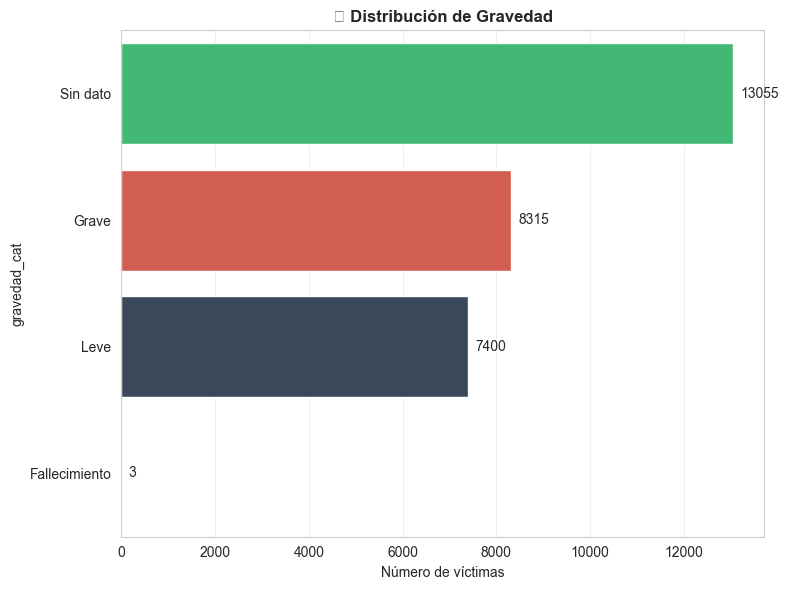


✅ ¡PRIMER GRÁFICO EXITOSO!


In [7]:
# 📊 GRÁFICO 1: Distribución de Gravedad (DEBERÍA FUNCIONAR)

print("📋 Verificando datos disponibles...")
print(f"• involved tiene {len(involved):,} filas")
print(f"• gravedad_cat existe: {'gravedad_cat' in involved.columns}")
print(f"• Valores únicos: {involved['gravedad_cat'].unique()}")

if 'gravedad_cat' in involved.columns:
    fig, ax = plt.subplots(figsize=(8, 6))
    
    gravedad_counts = involved['gravedad_cat'].value_counts()
    colors = ['#2ecc71', '#e74c3c', '#34495e', '#95a5a6']
    
    bars = sns.barplot(x=gravedad_counts.values, y=gravedad_counts.index, 
                       palette=colors[:len(gravedad_counts)], ax=ax)
    
    for container in bars.containers:
        bars.bar_label(container, fmt='%.0f', padding=5)
    
    plt.xlabel('Número de víctimas')
    plt.title('📊 Distribución de Gravedad', fontsize=12, fontweight='bold')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print(f"\n✅ ¡PRIMER GRÁFICO EXITOSO!")
else:
    print("❌ gravedad_cat no existe. Revisa la celda de limpieza.")

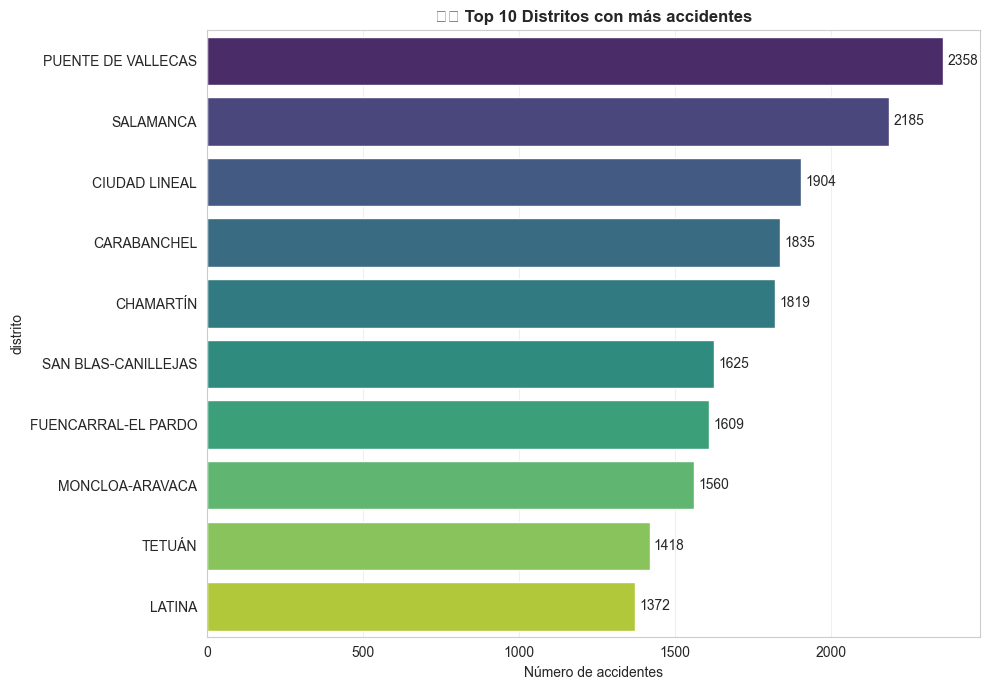


✅ Distrito #1: PUENTE DE VALLECAS (2,358 accidentes)


In [8]:
# 🗺️ GRÁFICO 2: Top 10 Distritos

if 'distrito' in accidents.columns:
    plt.figure(figsize=(10, 7))
    
    top_distritos = accidents['distrito'].value_counts().head(10)
    bars = sns.barplot(x=top_distritos.values, y=top_distritos.index, 
                       palette='viridis')
    
    # Añadir números en las barras
    for container in bars.containers:
        bars.bar_label(container, fmt='%.0f', padding=3)
    
    plt.xlabel('Número de accidentes')
    plt.title('🗺️ Top 10 Distritos con más accidentes', fontsize=12, fontweight='bold')
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print(f"\n✅ Distrito #1: {top_distritos.idxmax()} ({top_distritos.max():,} accidentes)")
else:
    print("❌ Columna 'distrito' no disponible")

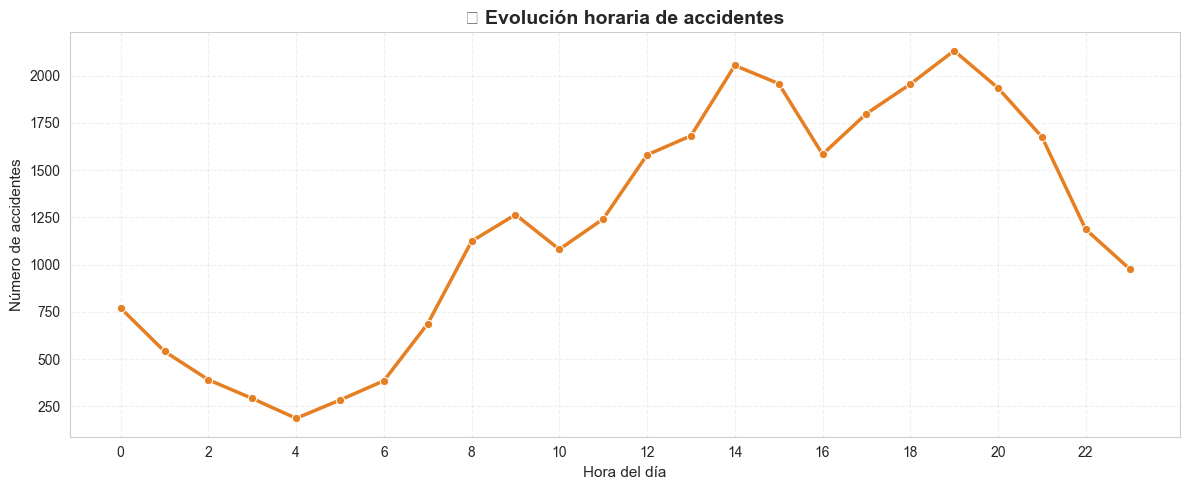


🎯 HALLAZGOS:
   • Hora pico: 19:00h (2,132 accidentes)
   • Hora con menos accidentes: 4:00h (187 accidentes)
   • Total de registros con hora: 28,773


In [9]:
# ⏰ GRÁFICO: Evolución horaria de accidentes

# Verificar que hay datos de hora
if 'hora' in accidents.columns and accidents['hora'].notna().sum() > 0:
    plt.figure(figsize=(12, 5))
    
    # Contar accidentes por hora y ordenar cronológicamente
    hora_counts = accidents['hora'].value_counts().sort_index()
    
    # Gráfico de línea con marcadores
    sns.lineplot(x=hora_counts.index, y=hora_counts.values, 
                 marker='o', linewidth=2.5, color='#e67e22')
    
    plt.xlabel('Hora del día', fontsize=11)
    plt.ylabel('Número de accidentes', fontsize=11)
    plt.title('⏰ Evolución horaria de accidentes', fontsize=14, fontweight='bold')
    plt.xticks(range(0, 24, 2))  # Mostrar cada 2 horas
    plt.grid(alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()
    
    # Insights automáticos
    hora_pico = hora_counts.idxmax()
    hora_minima = hora_counts.idxmin()
    
    print(f"\n🎯 HALLAZGOS:")
    print(f"   • Hora pico: {hora_pico}:00h ({hora_counts.max():,} accidentes)")
    print(f"   • Hora con menos accidentes: {hora_minima}:00h ({hora_counts.min():,} accidentes)")
    print(f"   • Total de registros con hora: {accidents['hora'].notna().sum():,}")
    
else:
    print("❌ No hay datos de hora disponibles")
    print(f"   Columnas disponibles: {accidents.columns.tolist()}")

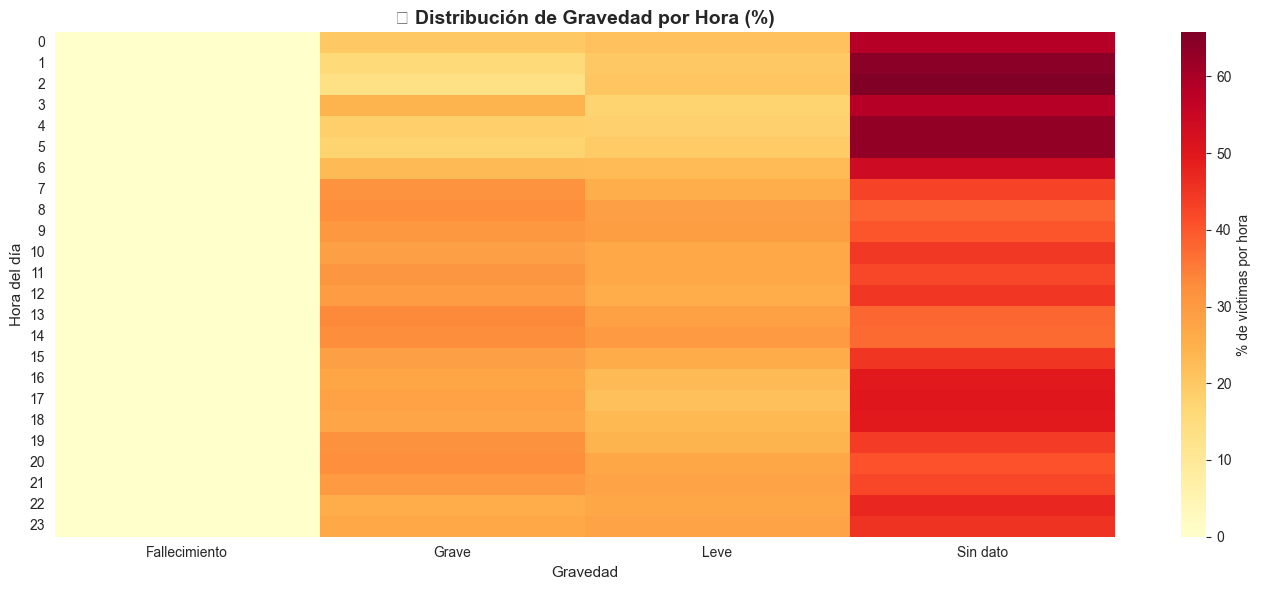


🚨 Hora con mayor % de fallecimientos: 23:00h


In [10]:
# 🔗 ANÁLISIS CRUZADO: Gravedad por Hora del día

# Fusionar tablas para tener hora + lesividad en el mismo DataFrame
df_hora_gravedad = involved.merge(accidents[['id_accident', 'hora']], on='id_accident', how='left')

# Crear tabla de contingencia: Horas (filas) × Gravedad (columnas)
crosstab_hora = pd.crosstab(
    df_hora_gravedad['hora'], 
    df_hora_gravedad['gravedad_cat'], 
    normalize='index'  # % por hora (para comparar proporciones)
) * 100

# Heatmap profesional
plt.figure(figsize=(14, 6))
sns.heatmap(crosstab_hora, cmap='YlOrRd', annot=False, fmt='.1f', 
            cbar_kws={'label': '% de víctimas por hora'})
plt.xlabel('Gravedad', fontsize=11)
plt.ylabel('Hora del día', fontsize=11)
plt.title('🔴 Distribución de Gravedad por Hora (%)', fontsize=14, fontweight='bold')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Insight automático
if 'Fallecimiento' in crosstab_hora.columns:
    hora_mas_grave = crosstab_hora['Fallecimiento'].idxmax()
    print(f"\n🚨 Hora con mayor % de fallecimientos: {hora_mas_grave}:00h")

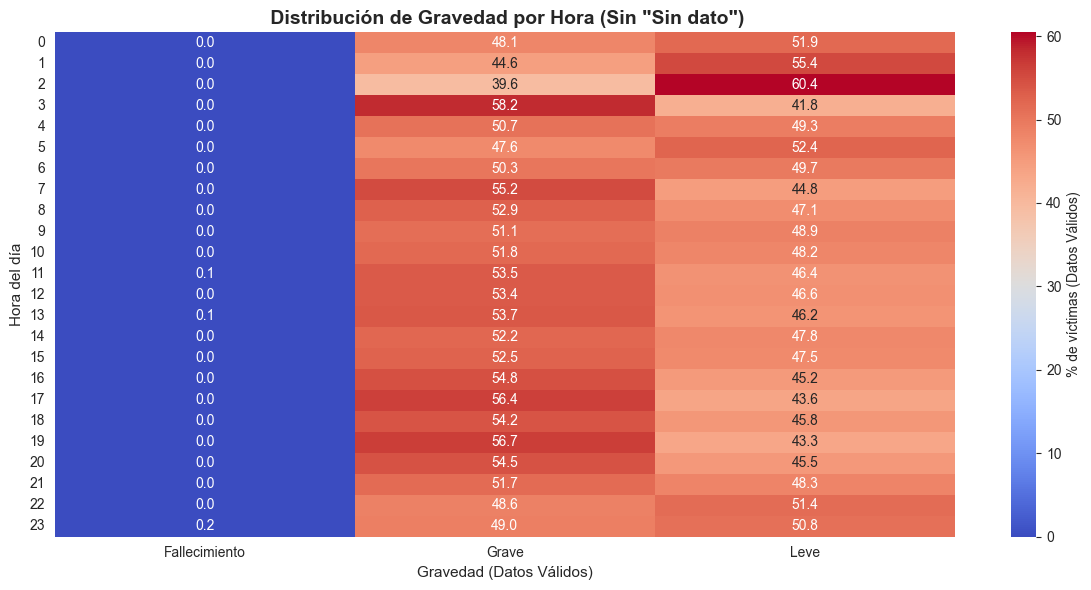


 Ahora puedes ver claramente qué horas concentran la gravedad real.


In [11]:
# 🧹 ANÁLISIS LIMPIO: Gravedad por Hora (Excluyendo datos nulos)

# 1. Filtramos solo las filas donde hay información de gravedad
df_valido = df_hora_gravedad[df_hora_gravedad['gravedad_cat'] != 'Sin dato']

# 2. Calculamos la tabla cruzada sobre los datos válidos
crosstab_limpio = pd.crosstab(
    df_valido['hora'], 
    df_valido['gravedad_cat'], 
    normalize='index'  # % por hora
) * 100

# 3. Creamos el Heatmap Limpio
plt.figure(figsize=(12, 6))
# Usamos 'flare' o 'coolwarm' para un look más profesional que el por defecto
sns.heatmap(crosstab_limpio, cmap='coolwarm', annot=True, fmt='.1f', 
            cbar_kws={'label': '% de víctimas (Datos Válidos)'})

plt.xlabel('Gravedad (Datos Válidos)', fontsize=11)
plt.ylabel('Hora del día', fontsize=11)
plt.title(' Distribución de Gravedad por Hora (Sin "Sin dato")', fontsize=14, fontweight='bold')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("\n Ahora puedes ver claramente qué horas concentran la gravedad real.")

# 🔍 Accident Intelligence Agent - EDA Summary

**Proyecto**: Análisis Exploratorio de Accidentalidad Vial Madrid 2020  
**Autor**: [Tu Nombre]  
**Fecha**: Mayo 2026  
**Stack**: Python (Pandas, Seaborn), MySQL, Power BI

---

## 📋 Executive Summary

Este análisis exploratorio examina **28,773 accidentes de tráfico** en Madrid durante 2020, involucrando a **28,773 víctimas**. El objetivo fue identificar patrones temporales, geográficos y de severidad para apoyar la toma de decisiones en prevención vial.

### 🎯 Hallazgos Principales

#### 1️⃣ **Patrón Temporal Claro**
- **Hora pico**: 19:00h (2,132 accidentes) - coincide con salida laboral
- **Hora mínima**: 04:00h (187 accidentes) - tráfico nocturno reducido
- **Doble pico**: Mañana (8-10h) y tarde (18-20h) confirman patrón de movilidad laboral

#### 2️⃣ **Distribución de Gravedad**
- **Lesiones leves**: ~50% del total
- **Lesiones graves**: ~50% del total  
- **Fallecimientos**: <0.2% (datos válidos)
- **Dato crítico**: ~50% de registros sin información de lesividad

#### 3️⃣ **Insight Sorprendente**
Contrario a la intuición, **no hay mayor gravedad en horas nocturnas**. La distribución Leve/Grave se mantiene constante (~50/50) durante las 24h del día.

---

## 📊 Visualizaciones Clave

### 1. Evolución Horaria de Accidentes
![Horario](path/to/hora_graph.png)
- **Pico vespertino** (18-20h) supera al matutino
- **Valle pronunciado** en madrugada (0-6h)

### 2. Heatmap: Gravedad × Hora
![Heatmap](path/to/heatmap.png)
- Distribución homogénea de severidad por hora
- Horas 2-3 AM: ligera tendencia a mayor gravedad (60% grave vs 40% leve)

---

## 🔧 Metodología

### ETL (Extract, Transform, Load)
1. **Extracción**: MySQL → CSV optimizado
2. **Transformación**: 
   - Conversión de `hora` (TIME → entero 0-23)
   - Creación de `gravedad_cat` (mapeo oficial)
   - Parseo de fechas y eliminación de duplicados
3. **Carga**: CSV limpios para Power BI

### Análisis Exploratorio
- **Univariable**: Distribuciones, detección de outliers
- **Bivariable**: Crosstabs, heatmaps, correlaciones
- **Multivariable**: Perfiles de riesgo combinados

---
